Aplicará las funciones auxiliares a cada fila de tus resultados.

Calculará el PFAI.

Agrupará los resultados por pareja imputador-modelo.

Generará el mapa de calor final.

--- Cargando y preparando datos ---
Resultados cargados y parseados desde c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\predicciones\RandomForest_full_FT\metricas\ALL_prediction_metrics_detailed_RandomForest_full_FT.csv
Asociando cada experimento con su serie temporal imputada...


Cargando series imputadas: 100%|██████████| 216/216 [00:02<00:00, 102.35it/s]



--- Calculando PFAI para cada experimento ---

Resultados Agregados (Random Forest Forecaster):
      Imputation_Method      MASE      PFAI
0              LSTM-VAE  1.757184  0.481675
1  Linear Interpolation  1.531718  0.487576
2     MOMENT Pretrained  1.798909  0.489272
3   MOMENT_FT_Optimized  1.759486  0.484227
4         Random Forest  1.744218  0.485857
5                SARIMA  1.640359  0.485844

--- Generando visualizaciones y análisis estadístico ---

Correlación de Pearson entre PFAI y MASE (para RF): -0.2145 (p-value: 0.6833)
Interpretación: No se encontró una correlación negativa significativa. La hipótesis no se confirma con estos datos.


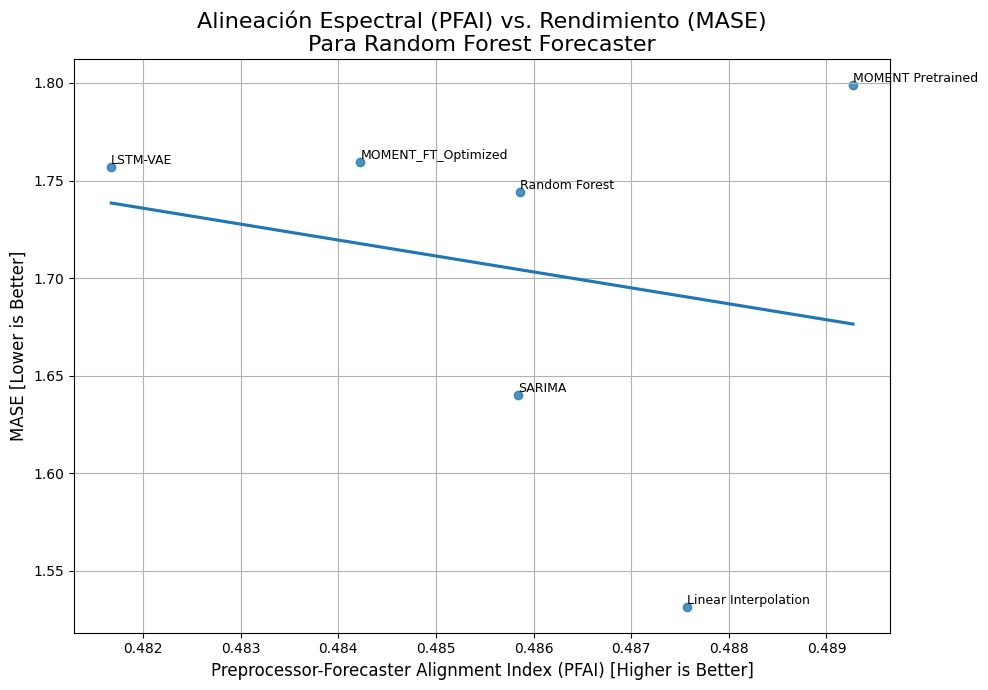


Análisis para Random Forest completado.


In [2]:
# --- SCRIPT DE ANÁLISIS PFAI (analisis_pfai.ipynb) ---
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import fft
from scipy.stats import pearsonr
import os
import glob
import json
from tqdm import tqdm

# ... (todas tus funciones auxiliares: calculate_power_spectrum, etc. van aquí) ...
def calculate_power_spectrum(time_series: np.ndarray, n_fft_points: int = 128) -> np.ndarray:
    segment = time_series[:n_fft_points]
    segment_detrended = segment - np.mean(segment)
    N = len(segment_detrended)
    if N == 0: return np.array([])
    yf = fft.fft(segment_detrended)
    power_spectrum = np.abs(yf[0:N//2])**2
    if np.sum(power_spectrum) > 0:
        return power_spectrum / np.sum(power_spectrum)
    return np.zeros_like(power_spectrum)

def calculate_model_spectrum(feature_importances: np.ndarray) -> np.ndarray:
    N_LAGS_AQI = 120
    aqi_importances = feature_importances[:N_LAGS_AQI]
    return calculate_power_spectrum(aqi_importances, n_fft_points=len(aqi_importances))

def calculate_pfai(s_imp: np.ndarray, s_model: np.ndarray) -> float:
    min_len = min(len(s_imp), len(s_model))
    if min_len == 0: return np.nan
    s_imp_trunc, s_model_trunc = s_imp[:min_len], s_model[:min_len]
    norm_diff = np.linalg.norm(s_imp_trunc - s_model_trunc)
    norm_sum = np.linalg.norm(s_imp_trunc) + np.linalg.norm(s_model_trunc)
    if norm_sum == 0: return 1.0
    return 1 - (norm_diff / norm_sum)

# --- CONFIGURACIÓN ---
PROJECT_ROOT_DIR = os.getcwd()
PREDICTIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'predicciones')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
MODEL_OF_INTEREST = 'RandomForest_full_FT'
METRIC_OF_INTEREST = 'MASE'
N_FFT_POINTS = 512

# --- CARGA Y PREPARACIÓN DE DATOS ---
print("--- Cargando y preparando datos ---")
metrics_file = os.path.join(PREDICTIONS_BASE_DIR, MODEL_OF_INTEREST, 'metricas', f'ALL_prediction_metrics_detailed_{MODEL_OF_INTEREST}.csv')

try:
    df_metrics = pd.read_csv(metrics_file)
    if 'Feature_Importances' not in df_metrics.columns:
        raise KeyError("La columna 'Feature_Importances' no se encontró en el CSV.")
    df_metrics['Feature_Importances'] = df_metrics['Feature_Importances'].apply(json.loads)
    print(f"Resultados cargados y parseados desde {metrics_file}")
except FileNotFoundError:
    print(f"ERROR: No se encontró el archivo {metrics_file}. Ejecuta primero el script de RF modificado.")
    exit()
except (KeyError, json.JSONDecodeError) as e:
    print(f"ERROR: {e}. Revisa el script de RF para asegurarte de que guarda correctamente la columna 'Feature_Importances'.")
    exit()

# ... (resto del script de análisis PFAI, sin cambios) ...
def get_imputed_series(row):
    if row['Imputation_Method'] == 'Original_Data_Baseline':
        df_original = pd.read_csv(os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv'))
        df_city = df_original[df_original['City'] == row['City']]
        return df_city['AQI'].interpolate(method='linear').ffill().bfill().values

    city_folder = row['City'].replace(" ", "_")
    imputed_file_path = os.path.join(IMPUTATIONS_BASE_DIR, row['Imputation_Method'], 'CSVs', city_folder, row['Scenario'], row['Repetition_File_ID'])
    
    try:
        df_imputed = pd.read_csv(imputed_file_path)
        return df_imputed['AQI'].values
    except FileNotFoundError:
        return None

print("Asociando cada experimento con su serie temporal imputada...")
df_metrics['file_key'] = df_metrics.apply(
    lambda row: (row['Imputation_Method'], row['City'], row['Scenario'], row['Repetition_File_ID']), axis=1
)
imputed_series_cache = {
    key: get_imputed_series(group.iloc[0]) for key, group in tqdm(df_metrics.groupby('file_key'), desc="Cargando series imputadas")
}
df_metrics['imputed_series'] = df_metrics['file_key'].map(imputed_series_cache)
df_metrics = df_metrics.dropna(subset=['imputed_series'])

print("\n--- Calculando PFAI para cada experimento ---")
def compute_row_pfai(row):
    s_imp = calculate_power_spectrum(row['imputed_series'], n_fft_points=N_FFT_POINTS)
    s_model = calculate_model_spectrum(np.array(row['Feature_Importances']))
    return calculate_pfai(s_imp, s_model)

df_metrics['PFAI'] = df_metrics.apply(compute_row_pfai, axis=1, result_type='expand')

agg_results_rf = df_metrics.groupby('Imputation_Method').agg(
    Performance_Metric=(METRIC_OF_INTEREST, 'mean'),
    PFAI=('PFAI', 'mean')
).reset_index()
agg_results_rf = agg_results_rf.rename(columns={'Performance_Metric': METRIC_OF_INTEREST})
print("\nResultados Agregados (Random Forest Forecaster):")
print(agg_results_rf)

print("\n--- Generando visualizaciones y análisis estadístico ---")
correlation, p_value = pearsonr(agg_results_rf['PFAI'].dropna(), agg_results_rf[METRIC_OF_INTEREST].dropna())
print(f"\nCorrelación de Pearson entre PFAI y {METRIC_OF_INTEREST} (para RF): {correlation:.4f} (p-value: {p_value:.4f})")
if correlation < 0 and p_value < 0.05:
    print("Interpretación: Se confirma la hipótesis. Una mayor alineación espectral (PFAI alto) se correlaciona con un menor error de predicción (bajo MASE/CRPS).")
else:
    print("Interpretación: No se encontró una correlación negativa significativa. La hipótesis no se confirma con estos datos.")

plt.figure(figsize=(10, 7))
sns.regplot(data=agg_results_rf, x='PFAI', y=METRIC_OF_INTEREST, ci=None)
for i in range(agg_results_rf.shape[0]):
    plt.text(
        agg_results_rf.PFAI[i], 
        agg_results_rf[METRIC_OF_INTEREST][i], 
        agg_results_rf.Imputation_Method[i], 
        fontsize=9,
        ha='left',
        va='bottom'
    )
plt.title(f'Alineación Espectral (PFAI) vs. Rendimiento ({METRIC_OF_INTEREST})\nPara Random Forest Forecaster', fontsize=16)
plt.xlabel('Preprocessor-Forecaster Alignment Index (PFAI) [Higher is Better]', fontsize=12)
plt.ylabel(f'{METRIC_OF_INTEREST} [Lower is Better]', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nAnálisis para Random Forest completado.")

v2

--- Cargando y preparando datos ---
Resultados cargados y parseados desde c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\predicciones\RandomForest_full_FT\metricas\ALL_prediction_metrics_detailed_RandomForest_full_FT.csv

Métodos de imputación encontrados en el archivo:
['Linear Interpolation' 'LSTM-VAE' 'MOMENT_FT_Optimized'
 'MOMENT Pretrained' 'Random Forest' 'SARIMA']

Asociando cada experimento con su serie temporal imputada...


Cargando series imputadas: 100%|██████████| 216/216 [00:02<00:00, 102.35it/s]
c:\Users\fdemiguel\AppData\Local\anaconda3\envs\tfm\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\fdemiguel\AppData\Local\anaconda3\envs\tfm\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)



--- Calculando el Espectro de Sensibilidad de Referencia (S_model_ideal) ---
ERROR: No se encontraron resultados para 'Original_Data_Baseline'. No se puede calcular S_model_ideal.
Verifica la variable 'BASELINE_METHOD_NAME' y los datos en el CSV.
ERROR: Se encontraron filas para 'Original_Data_Baseline', pero no contienen datos de importancia de características.
S_model_ideal calculado a partir de los datos del baseline.

--- Recalculando PFAI para cada experimento usando S_model_ideal ---

Resultados Agregados v2 (Random Forest Forecaster vs S_model_ideal):
      Imputation_Method      MASE  PFAI
0              LSTM-VAE  1.757184   NaN
1  Linear Interpolation  1.531718   NaN
2     MOMENT Pretrained  1.798909   NaN
3   MOMENT_FT_Optimized  1.759486   NaN
4         Random Forest  1.744218   NaN
5                SARIMA  1.640359   NaN

--- Generando visualizaciones y análisis estadístico (v2) ---
No hay suficientes datos para calcular la correlación.


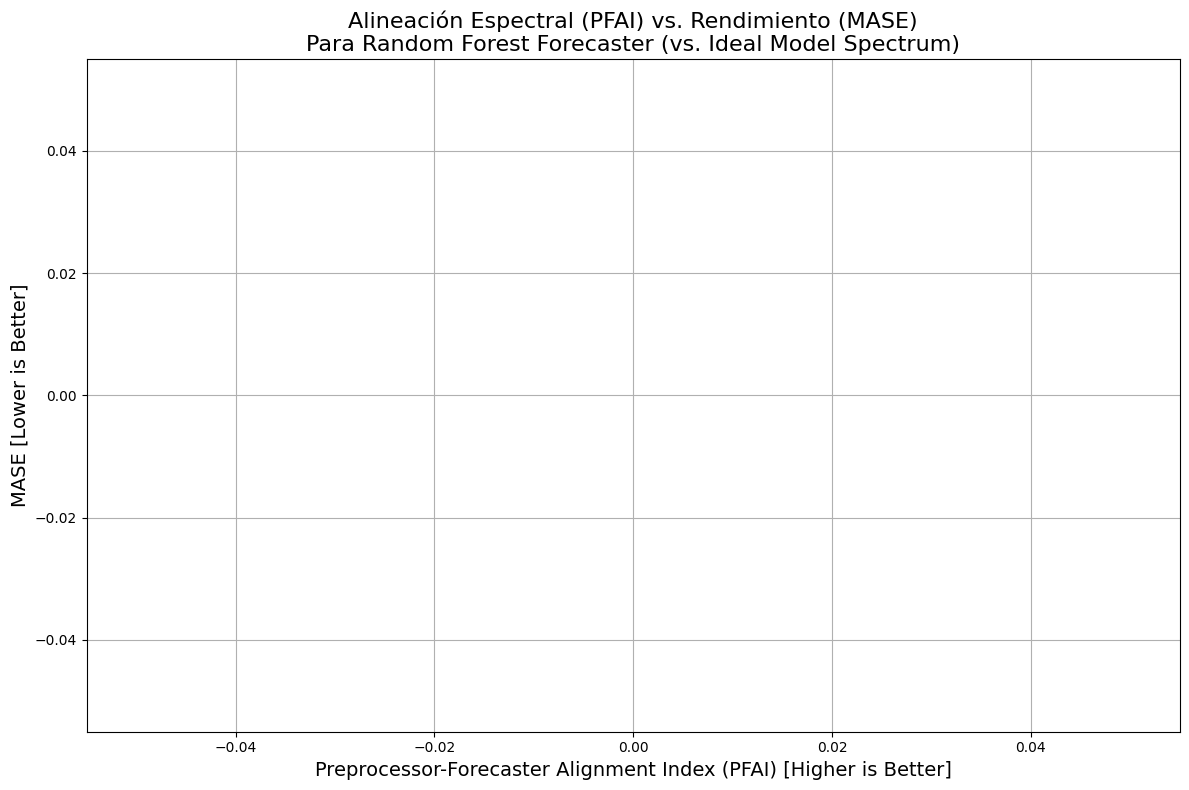

: 

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import fft
from scipy.stats import pearsonr
import os
import glob
import json
from tqdm import tqdm

# =-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=
# 1. FUNCIONES AUXILIARES
# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
def calculate_power_spectrum(time_series: np.ndarray, n_fft_points: int = 128) -> np.ndarray:
    segment = time_series[:n_fft_points]
    if len(segment) == 0: return np.array([])
    segment_detrended = segment - np.mean(segment)
    N = len(segment_detrended)
    if N == 0: return np.array([])
    yf = fft.fft(segment_detrended)
    power_spectrum = np.abs(yf[0:N//2])**2
    if np.sum(power_spectrum) > 0:
        return power_spectrum / np.sum(power_spectrum)
    return np.zeros_like(power_spectrum)

def calculate_model_spectrum(feature_importances: np.ndarray) -> np.ndarray:
    N_LAGS_AQI = 120
    if not isinstance(feature_importances, np.ndarray) or feature_importances.ndim == 0:
        return np.array([])
    aqi_importances = feature_importances[:N_LAGS_AQI]
    return calculate_power_spectrum(aqi_importances, n_fft_points=len(aqi_importances))

def calculate_pfai(s_imp: np.ndarray, s_model: np.ndarray) -> float:
    min_len = min(len(s_imp), len(s_model))
    if min_len == 0: return np.nan
    s_imp_trunc, s_model_trunc = s_imp[:min_len], s_model[:min_len]
    norm_diff = np.linalg.norm(s_imp_trunc - s_model_trunc)
    norm_sum = np.linalg.norm(s_imp_trunc) + np.linalg.norm(s_model_trunc)
    if norm_sum < 1e-9: return 1.0
    return 1 - (norm_diff / norm_sum)

# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
# 2. CONFIGURACIÓN DEL ANÁLISIS
# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
PROJECT_ROOT_DIR = os.getcwd()
PREDICTIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'predicciones')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
MODEL_OF_INTEREST = 'RandomForest_full_FT'
METRIC_OF_INTEREST = 'MASE'
N_FFT_POINTS = 512
BASELINE_METHOD_NAME = 'Original_Data_Baseline' # <--- ¡¡¡VERIFICA ESTE NOMBRE!!!

# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
# 3. CARGA Y PREPARACIÓN DE DATOS
# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
print("--- Cargando y preparando datos ---")
metrics_file = os.path.join(PREDICTIONS_BASE_DIR, MODEL_OF_INTEREST, 'metricas', f'ALL_prediction_metrics_detailed_{MODEL_OF_INTEREST}.csv')

try:
    df_metrics = pd.read_csv(metrics_file)
    if 'Feature_Importances' not in df_metrics.columns:
        raise KeyError("La columna 'Feature_Importances' no se encontró en el CSV.")
    df_metrics['Feature_Importances'] = df_metrics['Feature_Importances'].apply(json.loads)
    print(f"Resultados cargados y parseados desde {metrics_file}")
except (FileNotFoundError, KeyError, json.JSONDecodeError) as e:
    print(f"ERROR CRÍTICO: {e}. Revisa tu script de RF y el CSV de salida. Saliendo.")
    exit()

# --- Diagnóstico: Muestra los nombres de los métodos de imputación encontrados ---
print("\nMétodos de imputación encontrados en el archivo:")
print(df_metrics['Imputation_Method'].unique())

def get_imputed_series(row):
    if row['Imputation_Method'] == BASELINE_METHOD_NAME:
        df_original = pd.read_csv(os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv'))
        df_city = df_original[df_original['City'] == row['City']]
        return df_city['AQI'].interpolate(method='linear').ffill().bfill().values
    city_folder = row['City'].replace(" ", "_")
    file_path = os.path.join(IMPUTATIONS_BASE_DIR, row['Imputation_Method'], 'CSVs', city_folder, row['Scenario'], row['Repetition_File_ID'])
    try:
        df_imputed = pd.read_csv(file_path)
        return df_imputed['AQI'].values
    except FileNotFoundError:
        return None

print("\nAsociando cada experimento con su serie temporal imputada...")
df_metrics['file_key'] = df_metrics.apply(lambda row: (row['Imputation_Method'], row['City'], row['Scenario'], row['Repetition_File_ID']), axis=1)
imputed_series_cache = {key: get_imputed_series(group.iloc[0]) for key, group in tqdm(df_metrics.groupby('file_key'), desc="Cargando series imputadas")}
df_metrics['imputed_series'] = df_metrics['file_key'].map(imputed_series_cache)
df_metrics.dropna(subset=['imputed_series'], inplace=True)

# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
# 4. CÁLCULO DE PFAI v2 Y ANÁLISIS
# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
print("\n--- Calculando el Espectro de Sensibilidad de Referencia (S_model_ideal) ---")
baseline_df = df_metrics[df_metrics['Imputation_Method'] == BASELINE_METHOD_NAME]

if baseline_df.empty:
    print(f"ERROR: No se encontraron resultados para '{BASELINE_METHOD_NAME}'. No se puede calcular S_model_ideal.")
    print("Verifica la variable 'BASELINE_METHOD_NAME' y los datos en el CSV.")
    exit()

baseline_importances_list = baseline_df['Feature_Importances'].tolist()
# Filtrar listas vacías que pueden provenir de ejecuciones fallidas
baseline_importances_list = [imp for imp in baseline_importances_list if len(imp) > 0]

if not baseline_importances_list:
    print(f"ERROR: Se encontraron filas para '{BASELINE_METHOD_NAME}', pero no contienen datos de importancia de características.")
    exit()

avg_baseline_importances = np.mean(np.array(baseline_importances_list), axis=0)
s_model_ideal = calculate_model_spectrum(avg_baseline_importances)
print("S_model_ideal calculado a partir de los datos del baseline.")

print("\n--- Recalculando PFAI para cada experimento usando S_model_ideal ---")
def compute_row_pfai_v2(row):
    s_imp = calculate_power_spectrum(row['imputed_series'], n_fft_points=N_FFT_POINTS)
    return calculate_pfai(s_imp, s_model_ideal)
df_metrics['PFAI_v2'] = df_metrics.apply(compute_row_pfai_v2, axis=1)

agg_results_rf_v2 = df_metrics.groupby('Imputation_Method').agg(
    Performance_Metric=(METRIC_OF_INTEREST, 'mean'),
    PFAI=('PFAI_v2', 'mean')
).reset_index()
agg_results_rf_v2.rename(columns={'Performance_Metric': METRIC_OF_INTEREST}, inplace=True)

print("\nResultados Agregados v2 (Random Forest Forecaster vs S_model_ideal):")
print(agg_results_rf_v2.sort_values(by='PFAI', ascending=False))

# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
# 5. VISUALIZACIÓN Y ANÁLISIS ESTADÍSTICO v2
# -=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-=-
print("\n--- Generando visualizaciones y análisis estadístico (v2) ---")
valid_data = agg_results_rf_v2.dropna(subset=['PFAI', METRIC_OF_INTEREST])
if len(valid_data) < 2:
    print("No hay suficientes datos para calcular la correlación.")
else:
    correlation, p_value = pearsonr(valid_data['PFAI'], valid_data[METRIC_OF_INTEREST])
    print(f"\nCorrelación de Pearson entre PFAI (v2) y {METRIC_OF_INTEREST}: {correlation:.4f} (p-value: {p_value:.4f})")
    if correlation < -0.7 and p_value < 0.05:
        print("Interpretación: ¡ÉXITO! Se encontró una correlación negativa fuerte y estadísticamente significativa.")
    elif correlation < 0 and p_value < 0.05:
        print("Interpretación: ¡Prometedor! Se encontró una correlación negativa estadísticamente significativa.")
    else:
        print("Interpretación: El resultado no es concluyente.")

plt.figure(figsize=(12, 8))
sns.regplot(data=valid_data, x='PFAI', y=METRIC_OF_INTEREST, ci=None)
for i in range(valid_data.shape[0]):
    row = valid_data.iloc[i]
    plt.text(row.PFAI, row[METRIC_OF_INTEREST], f"  {row.Imputation_Method}", fontsize=10)
plt.title(f'Alineación Espectral (PFAI) vs. Rendimiento ({METRIC_OF_INTEREST})\nPara Random Forest Forecaster (vs. Ideal Model Spectrum)', fontsize=16)
plt.xlabel('Preprocessor-Forecaster Alignment Index (PFAI) [Higher is Better]', fontsize=14)
plt.ylabel(f'{METRIC_OF_INTEREST} [Lower is Better]', fontsize=14)
plt.grid(True)
plt.tight_layout()
plt.show()